# Test evaluation: the four final models

The single evaluation on the held-out test set, with every model and decision frozen beforehand: the large model
(c9) and the three compressed models (d6), each the seed-1738 run, and the tumour decision rule from c10
(argmax, except a cutoff of 0.283 on P(tumour) for the 1.4 kB model).

Two test sets: the **official** test split (889 images) and the **clean** test set (833), which leaves out the
test images that are near-copies of training images (c1). Clean test is the fair measure of generalisation; the
official split is what published results use.

In [1]:
import sys, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
sys.path.insert(0, "..")
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score, confusion_matrix
from lib.train import Config, build_model, prepare_data, predict, DEVICE, RESULTS, CKPT
from lib.data import ARTIFACTS, CLASSES, NO_TUMOR, load_split, GPUSplit
from lib.evaluation import bootstrap_ci, tumor_score

PICKS = json.loads((ARTIFACTS / "compress_final.json").read_text())        # the compressed models chosen in d6
MODELS = {"large": "c9/final_s1738", **{f"{p['stored kB']:.1f} kB": f"{p['record']}_s1738" for p in PICKS.values()}}
CUTOFF = json.loads((ARTIFACTS / "threshold.json").read_text())["decisions"]
TEACHER_BYTES = json.loads((ARTIFACTS / "compress_rules.json").read_text())["teacher"]["bytes"]

def macs(net, size):
    total = 0
    def hook(m, i, o):
        nonlocal total
        if isinstance(m, torch.nn.Conv2d):
            total += o.numel() * (m.in_channels // m.groups) * m.kernel_size[0] * m.kernel_size[1]
        elif isinstance(m, torch.nn.Linear):
            total += m.in_features * m.out_features
    hs = [m.register_forward_hook(hook) for m in net.modules()]
    with torch.no_grad():
        net.cpu().eval()(torch.zeros(1, 1, size, size))
    for h in hs: h.remove()
    return total

probs, info = {}, {}
for name, run in MODELS.items():
    rec = json.loads((RESULTS / f"{run}.json").read_text())
    cfg = Config(**{k: tuple(v) if isinstance(v, list) else v for k, v in rec["config"].items()})
    train, _ = prepare_data(cfg)                                   # train mean/std, as in training
    net = build_model(cfg, train.X.shape[1])
    net.load_state_dict(torch.load(CKPT / f"{run}.pt", map_location="cpu"))
    info[name] = {"stored kB": (rec["size"]["bytes"] if "size" in rec else TEACHER_BYTES) / 1024,
                  "parameters": sum(p.numel() for p in net.parameters()), "MMACs": macs(net, cfg.size) / 1e6,
                  "val": np.load(RESULTS / f"{run}_val.npz")}
    net.to(DEVICE)
    for clean in [False, True]:
        te = GPUSplit(load_split("test", cfg.mode, cfg.resize, cfg.size, clean=clean), DEVICE, train.mean, train.std,
                      cfg.normalize == "per_image")
        probs[name, clean] = (te.y.cpu().numpy(), predict(net, te))
print({k: len(v[0]) for k, v in list(probs.items())[:2]})

{('large', False): 889, ('large', True): 833}


## 1. Scores

In [2]:
def decide(prob, cutoff):
    if cutoff is None:
        return prob.argmax(1)
    p = prob.copy(); p[:, NO_TUMOR] = -1
    return np.where(tumor_score(prob) >= cutoff, p.argmax(1), NO_TUMOR)

rows = {}
for (name, clean), (y, prob) in probs.items():
    pred = decide(prob, CUTOFF[name]); tum = y != NO_TUMOR
    lo, hi = bootstrap_ci(y, pred)
    r4 = lambda v: round(float(v), 4)
    rows[(name, "clean" if clean else "official")] = {
        "bal. acc": r4(balanced_accuracy_score(y, pred)), "95 % CI": f"[{lo:.3f}, {hi:.3f}]",
        "accuracy": r4(accuracy_score(y, pred)), "macro-F1": r4(f1_score(y, pred, average="macro")),
        **{f"recall {c}": r4((pred[y == i] == i).mean()) for i, c in enumerate(CLASSES)},
        "tumour sens.": r4((pred[tum] != NO_TUMOR).mean()), "missed tumours": int((pred[tum] == NO_TUMOR).sum()),
        "tumour spec.": r4((pred[~tum] == NO_TUMOR).mean()), "false alarms": int((pred[~tum] != NO_TUMOR).sum()),
        "tumour AUC": r4(roc_auc_score(tum, tumor_score(prob)))}
S = pd.DataFrame(rows).T
display(S)
# val score of the same model under the same decision rule, for comparison
for name in info:
    v = info[name].pop("val")
    info[name]["val bal. acc"] = balanced_accuracy_score(v["y"], decide(v["prob"], CUTOFF[name]))

bal. acc         95 % CI accuracy macro-F1 recall glioma  \
large   official   0.9611  [0.947, 0.974]   0.9618   0.9586        0.9543   
        clean      0.9587  [0.942, 0.973]   0.9592   0.9555        0.9515   
9.3 kB  official   0.9391  [0.921, 0.955]   0.9381   0.9358        0.9238   
        clean      0.9366  [0.918, 0.953]   0.9364   0.9342        0.9256   
18.8 kB official   0.9535  [0.938, 0.968]   0.9561    0.953        0.9543   
        clean      0.9502  [0.934, 0.966]   0.9532   0.9493        0.9515   
1.4 kB  official    0.811  [0.783, 0.838]   0.8346   0.8225        0.9024   
        clean       0.807  [0.779, 0.835]   0.8307   0.8178        0.8997   

                 recall meningioma recall no_tumor recall pituitary  \
large   official            0.9412          0.9492              1.0   
        clean               0.9404          0.9429              1.0   
9.3 kB  official            0.9231          0.9322           0.9775   
        clean                0.922          0.9238           0.9751   
18.8 kB official            0.9412          0.9322           0.9865   
        clean               0.9404          0.9238           0.9851   
1.4 kB  official            0.6923          0.7034           0.9459   
        clean               0.6972          0.6857           0.9453   

                 tumour sens. missed tumours tumour spec. false alarms  \
large   official       0.9883              9       0.9492            6   
        clean          0.9876              9       0.9429            6   
9.3 kB  official        0.987             10       0.9322            8   
        clean           0.989              8       0.9238            8   
18.8 kB official       0.9896              8       0.9322            8   
        clean           0.989              8       0.9238            8   
1.4 kB  official       0.9896              8       0.7034           35   
        clean           0.989              8       0.6857           33   

                 tumour AUC  
large   official     0.9968  
        clean        0.9966  
9.3 kB  official     0.9945  
        clean        0.9943  
18.8 kB official     0.9973  
        clean         0.997  
1.4 kB  official      0.974  
        clean        0.9717

In [3]:
summary = pd.DataFrame(info).T
summary["test bal. acc (clean)"] = [S.loc[(n, "clean"), "bal. acc"] for n in summary.index]
summary["test bal. acc (official)"] = [S.loc[(n, "official"), "bal. acc"] for n in summary.index]
summary["test - val (clean)"] = summary["test bal. acc (clean)"] - summary["val bal. acc"]
display(summary.astype(float).round({"stored kB": 1, "MMACs": 1, "parameters": 0}).round(4))
y, prob = probs["large", True]
print("large model, clean test, confusion matrix (rows = true class):")
display(pd.DataFrame(confusion_matrix(y, decide(prob, None), labels=range(4)),
                     index=[f"true {c}" for c in CLASSES], columns=[f"pred {c}" for c in CLASSES]))
_ = (ARTIFACTS / "test_results.json").write_text(json.dumps(
    {f"{n} | {s}": {k: (float(v) if not isinstance(v, str) else v) for k, v in r.items()} for (n, s), r in rows.items()}, indent=1))

,stored kB,parameters,MMACs,val bal. acc,test bal. acc (clean),test bal. acc (official),test - val (clean)
large,1079.6,276628.0,72.1,0.9678,0.9587,0.9611,-0.0091
9.3 kB,9.3,13588.0,5.8,0.9441,0.9366,0.9391,-0.0075
18.8 kB,18.8,53796.0,28.3,0.9613,0.9502,0.9535,-0.0111
1.4 kB,1.4,1912.0,2.4,0.8119,0.8070,0.8110,-0.0049


large model, clean test, confusion matrix (rows = true class):


,pred glioma,pred meningioma,pred no_tumor,pred pituitary
true glioma,294,5,5,5
true meningioma,7,205,4,2
true no_tumor,2,2,99,2
true pituitary,0,0,0,201


## 2. Size and compute vs score

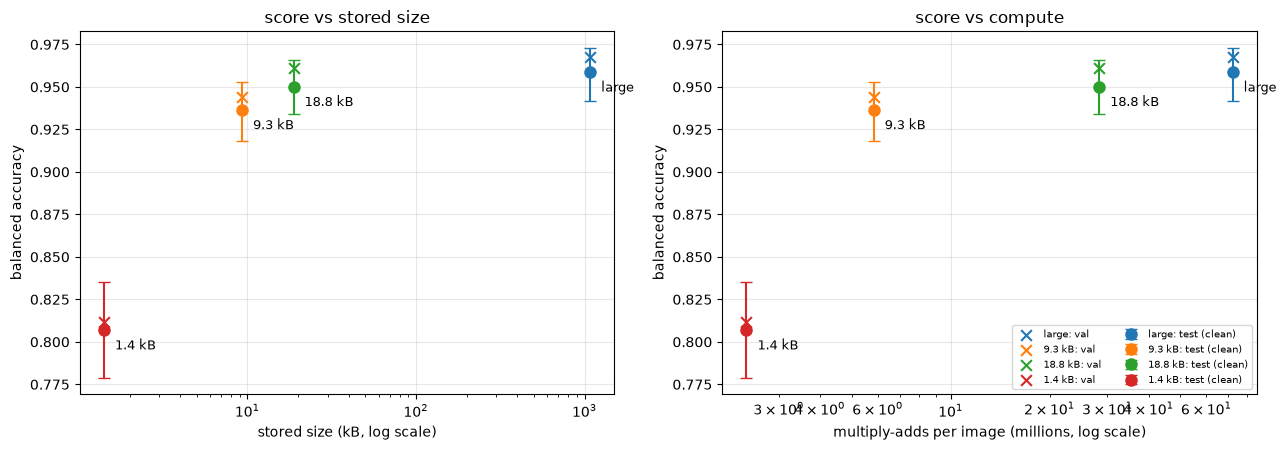

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, col, label in [(axes[0], "stored kB", "stored size (kB, log scale)"), (axes[1], "MMACs", "multiply-adds per image (millions, log scale)")]:
    for i, n in enumerate(summary.index):
        x = summary.loc[n, col]
        lo, hi = (float(v) for v in S.loc[(n, "clean"), "95 % CI"].strip("[]").split(","))
        t = summary.loc[n, "test bal. acc (clean)"]
        ax.errorbar(x, t, yerr=[[t - lo], [hi - t]], fmt="o", color=f"C{i}", capsize=4, ms=8, label=f"{n}: test (clean)")
        ax.scatter(x, summary.loc[n, "val bal. acc"], marker="x", s=60, color=f"C{i}", label=f"{n}: val")
        ax.annotate(n, (x, t), textcoords="offset points", xytext=(8, -14), fontsize=9)
    ax.set(xscale="log", xlabel=label, ylabel="balanced accuracy"); ax.grid(alpha=0.3)
axes[0].set_title("score vs stored size"); axes[1].set_title("score vs compute")
axes[1].legend(fontsize=7, loc="lower right", ncol=2)
plt.tight_layout(); plt.show()

**Result.** Balanced accuracy on the clean test set (833 images), with the val score of the same model under the
same decision rule for comparison:

| model | stored size | multiply-adds | val | **test (clean)** | test (official, 889) |
|---|---|---|---|---|---|
| large | 1,080 kB | 72 M | 0.968 | **0.959** [0.942, 0.973] | 0.961 |
| 18.8 kB | 18.8 kB | 28 M | 0.961 | **0.950** [0.934, 0.966] | 0.954 |
| 9.3 kB | 9.3 kB | 5.8 M | 0.944 | **0.937** [0.918, 0.953] | 0.939 |
| 1.4 kB | 1.4 kB | 2.4 M | 0.812 | **0.807** [0.779, 0.835] | 0.811 |

* **The val scores were optimistic, as expected, but only slightly.** Every model loses 0.5 to 1.1 pp from val to
  test, inside its confidence interval: selecting among hundreds of configurations on val cost about 1 pp.
* **The order of the models is the same as on val**, and the 57x smaller 18.8 kB model stays within 0.9 pp of the
  large one. The 9.3 kB model ends below the 0.95 floor it was chosen for on val (0.937); the 18.8 kB model, picked
  with a 1 pp margin for exactly this risk, holds it (0.950).
* **Tumour detection holds up**: on clean test every model catches 98.8 to 98.9 % of tumours (8 or 9 missed out
  of 728). The cost
  differs: 6 false alarms out of 105 healthy scans for the large model, 8 for the 18.8 and 9.3 kB models, and 33
  for the 1.4 kB model, whose cutoff trades specificity for sensitivity by design.
* **Official vs clean test** differ by at most 0.4 pp: the 56 near-copies of training images in the official split
  barely inflate the score.
* The main remaining error is still glioma vs meningioma (12 of the large model's 34 errors on clean test).
* For comparison, the dataset authors report test accuracy 0.847 for a CNN trained from scratch and 0.971 / 0.983
  for fine-tuned ImageNet ResNet50 / DenseNet121 (official split). The large model reaches accuracy 0.962 on the
  same split without pretraining, and the 1.4 kB model (accuracy 0.835) is close to their from-scratch CNN.